In [32]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os                  #Loads a system tool to talk to the computer's files and folders
import json
import time
import random
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)                     #Locks all random generators to that anchor, making sure our results are identical every time we run it.
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [8]:
# ============================================================
# CELL 2 - UPLOAD DATASET
# ============================================================

import io
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("File:", file_name)
print("Shape:", df.shape)
display(df.head())

Saving GSPC.csv to GSPC (3).csv
File: GSPC (3).csv
Shape: (24801, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1927-12-30,17.660000,17.660000,17.660000,17.660000,17.660000,0
1,1928-01-03,17.760000,17.760000,17.760000,17.760000,17.760000,0
2,1928-01-04,17.719999,17.719999,17.719999,17.719999,17.719999,0
3,1928-01-05,17.549999,17.549999,17.549999,17.549999,17.549999,0
4,1928-01-06,17.660000,17.660000,17.660000,17.660000,17.660000,0


In [9]:
# ============================================================
# CELL 3 - BASIC DATA INFORMATION
# ============================================================

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (24801, 7)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

Data Types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

Missing Values:


,Missing_Count
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0



Duplicate Rows: 0


In [10]:
# ============================================================
# CELL 4 - REQUIRED COLUMN VALIDATION
# ============================================================

required_columns = [
    "Date", "Open", "High", "Low",
    "Close", "Adj Close", "Volume"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")

All required columns are present.


In [11]:
# ============================================================
# CELL 5 - DATE CONVERSION + SORTING
# ============================================================

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

if df["Date"].isna().any():
    raise ValueError("Invalid Date values detected.")

df = (
    df.sort_values("Date")
      .drop_duplicates()
      .reset_index(drop=True)
)

print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())


Start Date: 1927-12-30 00:00:00
End Date: 2026-09-25 00:00:00


In [12]:
# ============================================================
# CELL 6 - OHLC VALIDATION
# ============================================================

invalid_ohlc = (
    (df["High"] < df["Low"]) |
    (df["High"] < df["Open"]) |
    (df["High"] < df["Close"]) |
    (df["Low"] > df["Open"]) |
    (df["Low"] > df["Close"])
)

print("Invalid OHLC rows:", int(invalid_ohlc.sum()))
print("Zero Volume rows:", int((df["Volume"] == 0).sum()))

Invalid OHLC rows: 0
Zero Volume rows: 5497


In [14]:
# ============================================================
# CELL 7 - EDA: MISSING VALUES
# ============================================================

missing = df.isnull().sum()

if missing.sum() > 0:
    plt.figure(figsize=(10, 5))
    missing[missing > 0].plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

No missing values found in the dataset.


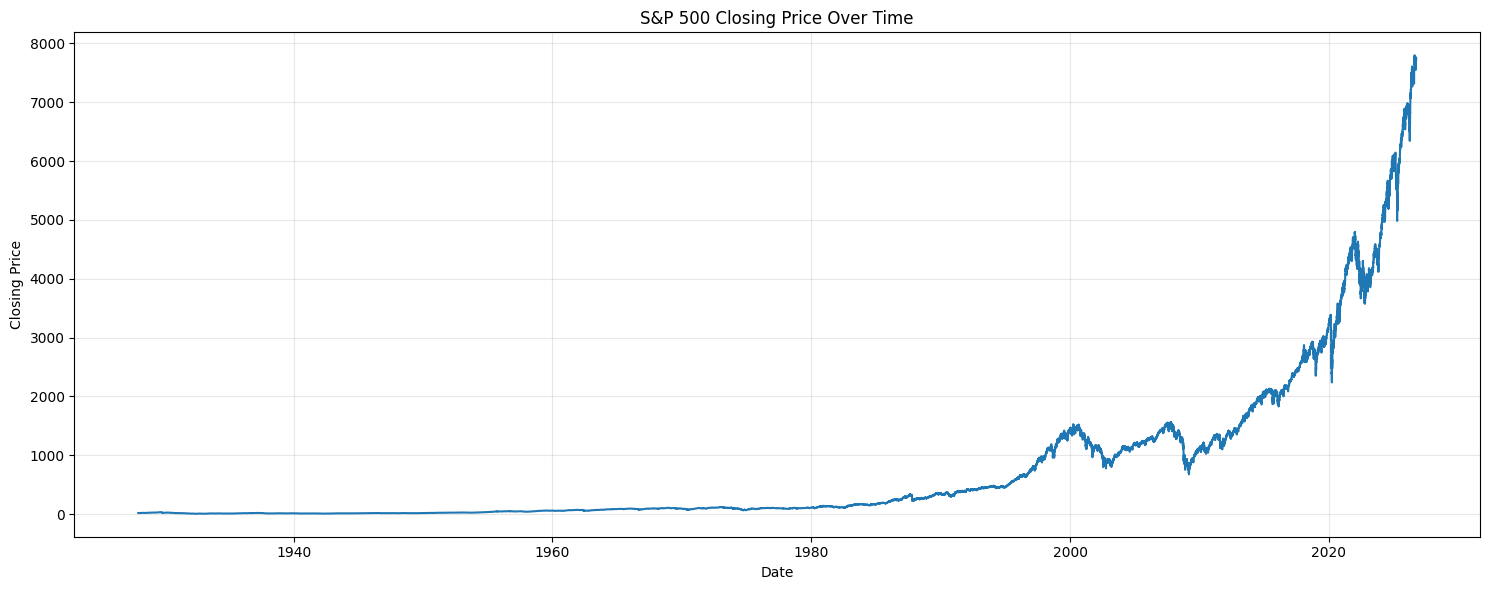

In [15]:
# ============================================================
# CELL 8 - EDA: CLOSING PRICE
# ============================================================

plt.figure(figsize=(15, 6))
plt.plot(df["Date"], df["Close"])
plt.title("S&P 500 Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


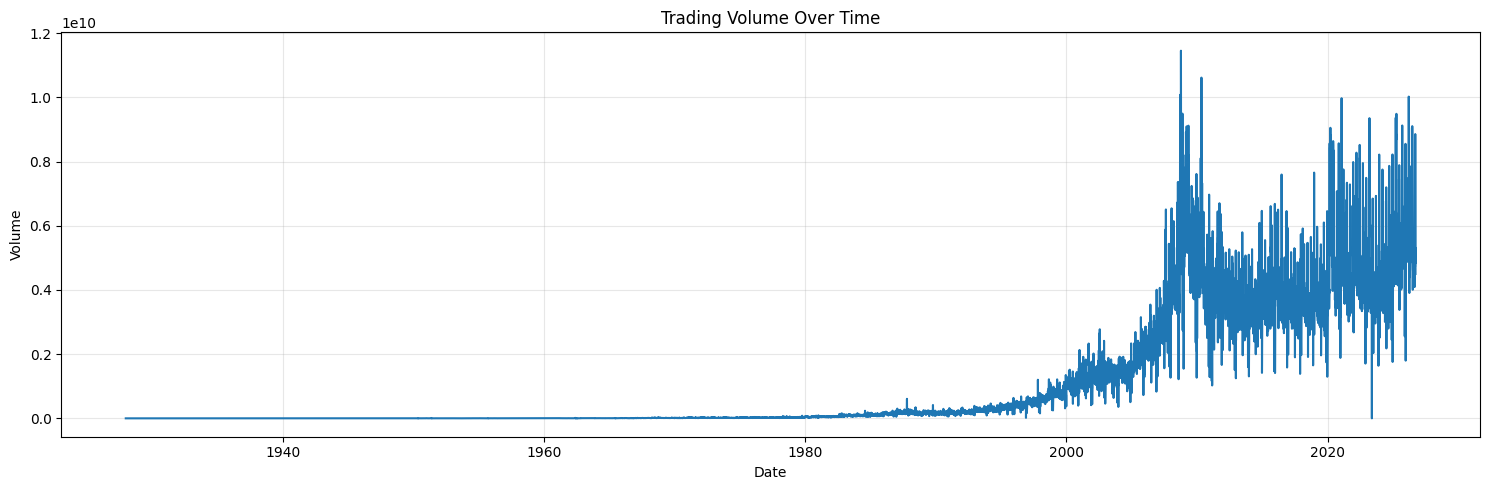

In [16]:
# ============================================================
# CELL 9 - EDA: VOLUME
# ============================================================

plt.figure(figsize=(15, 5))
plt.plot(df["Date"], df["Volume"])
plt.title("Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [17]:
# ============================================================
# CELL 10 - FEATURE ENGINEERING
# ============================================================

df["Daily_Return"] = df["Close"].pct_change()

df["Price_Range_Pct"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

df["Open_Close_Pct"] = (
    (df["Close"] - df["Open"]) / df["Open"]
)

df["MA7"] = df["Close"].rolling(7).mean()
df["MA20"] = df["Close"].rolling(20).mean()

df["Close_MA7_Ratio"] = (
    df["Close"] / df["MA7"]
)

df["Close_MA20_Ratio"] = (
    df["Close"] / df["MA20"]
)

df["Volatility_20"] = (
    df["Daily_Return"].rolling(20).std()
)

df["MA7_MA20_Cross"] = (
    df["MA7"] / df["MA20"]
)

df["Momentum_5"] = (
    df["Close"] / df["Close"].shift(5) - 1
)

df["Momentum_10"] = (
    df["Close"] / df["Close"].shift(10) - 1
)

df["Target_Return"] = (
    df["Close"].shift(-1) / df["Close"] - 1
)

print("Feature engineering completed.")


Feature engineering completed.


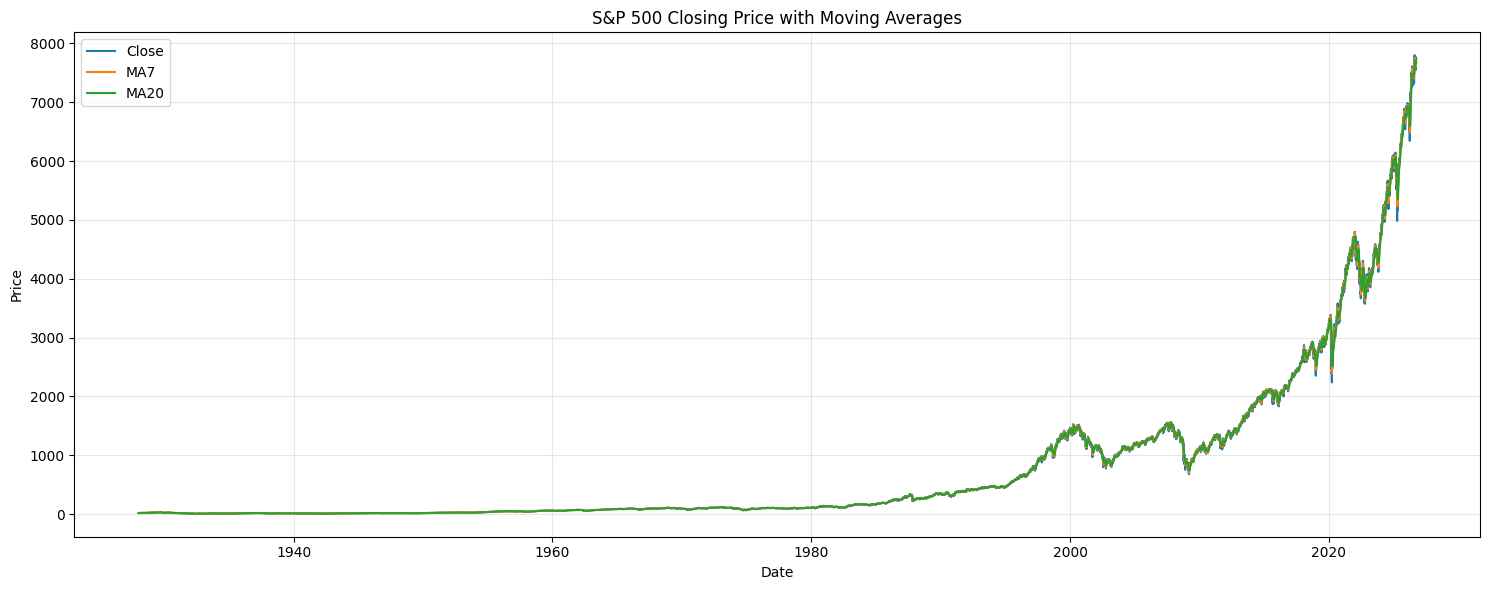

In [18]:
# ============================================================
# CELL 11 - EDA: MOVING AVERAGES
# ============================================================

plt.figure(figsize=(15, 6))
plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["MA7"], label="MA7")
plt.plot(df["Date"], df["MA20"], label="MA20")
plt.title("S&P 500 Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


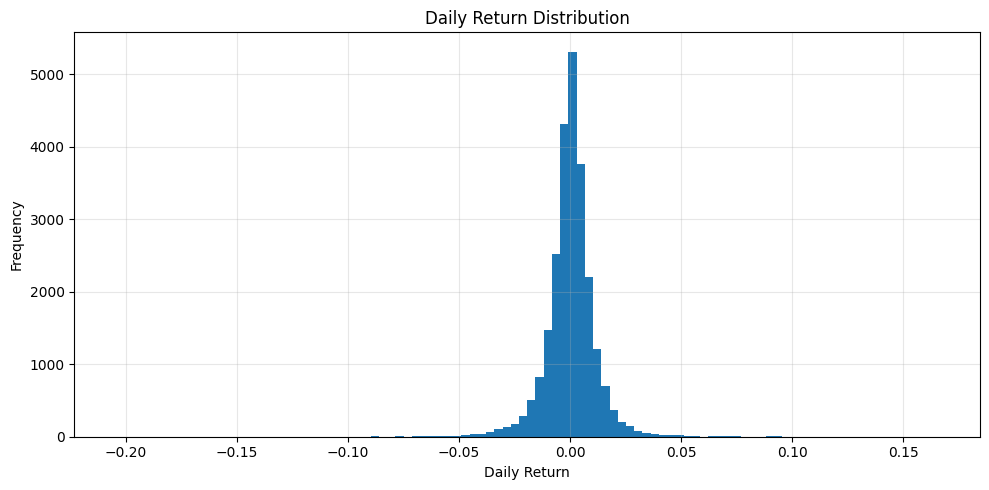

In [19]:
# ============================================================
# CELL 12 - EDA: DAILY RETURN DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))
plt.hist(
    df["Daily_Return"].dropna(),
    bins=100
)
plt.title("Daily Return Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:
# ============================================================
# CELL 13 - DEFINE FEATURES
# ============================================================

FEATURES = [
    "Daily_Return",
    "Price_Range_Pct",
    "Open_Close_Pct",
    "Close_MA7_Ratio",
    "Close_MA20_Ratio",
    "Volatility_20",
    "MA7_MA20_Cross",
    "Momentum_5",
    "Momentum_10"
]

TARGET = "Target_Return"


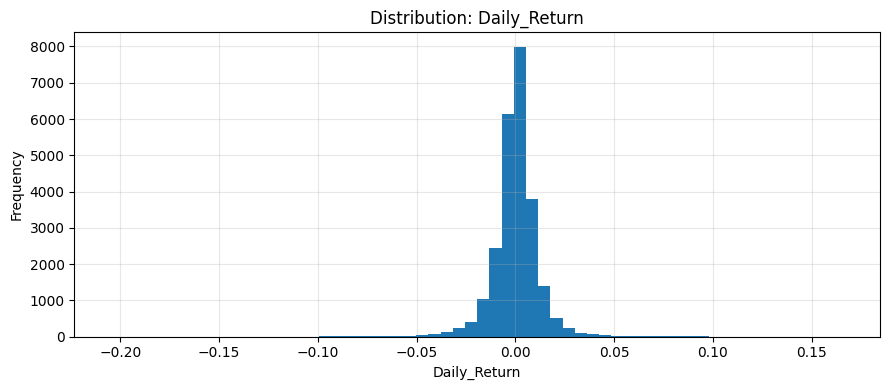

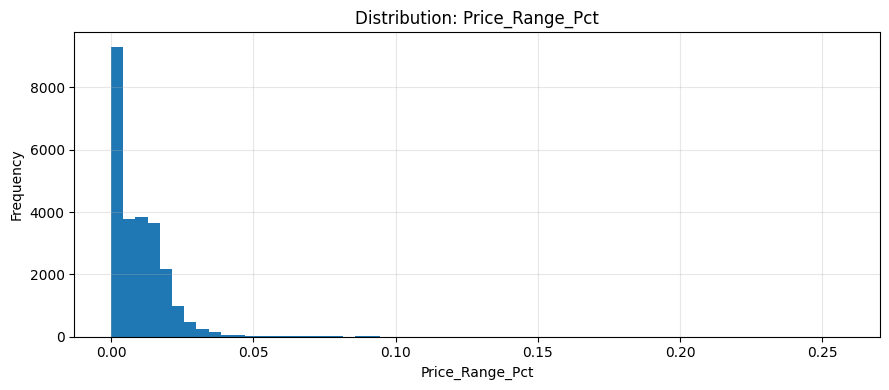

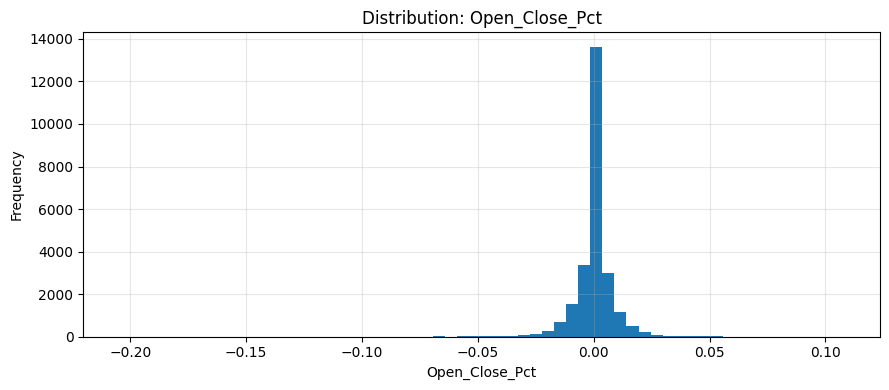

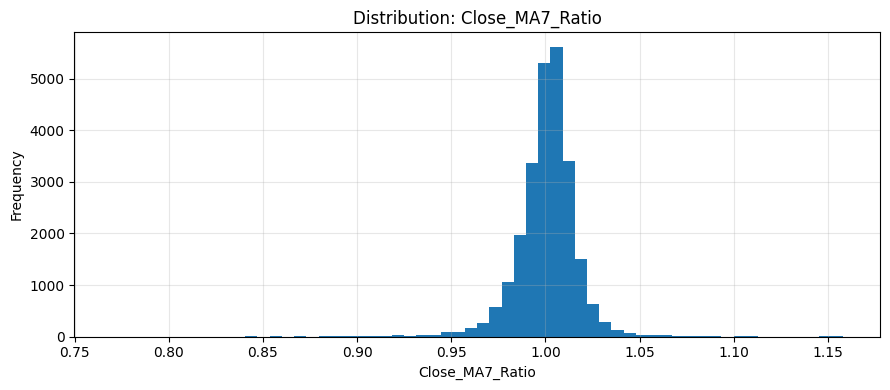

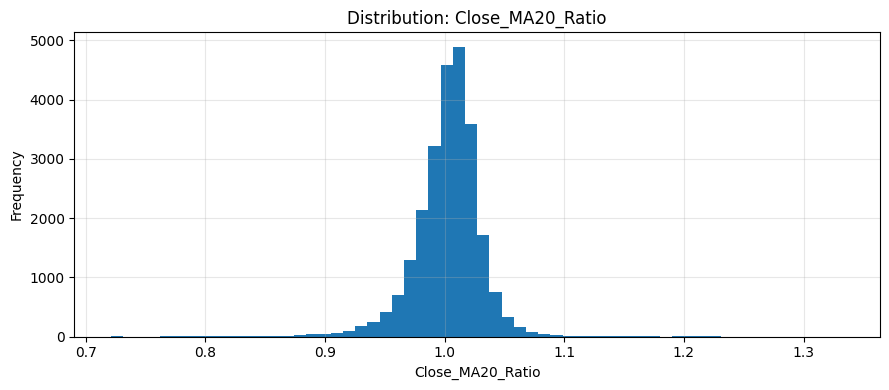

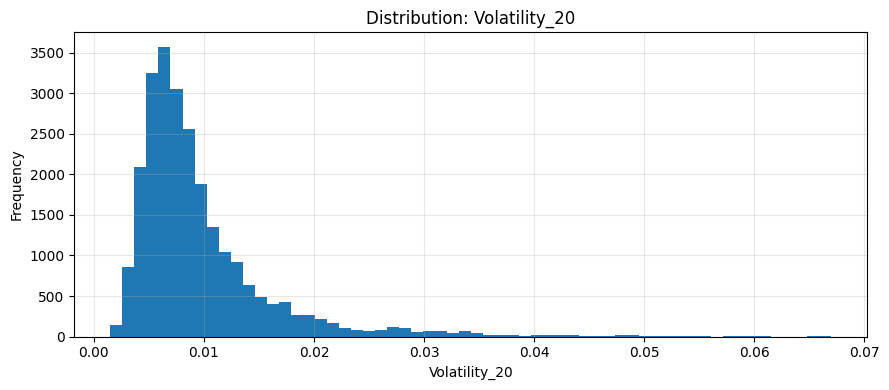

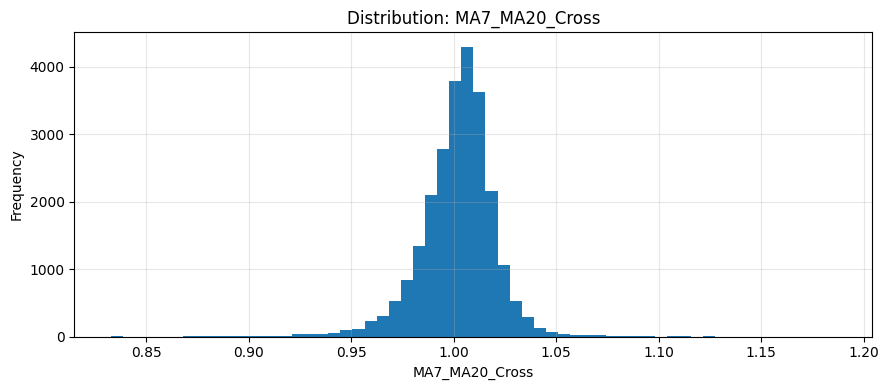

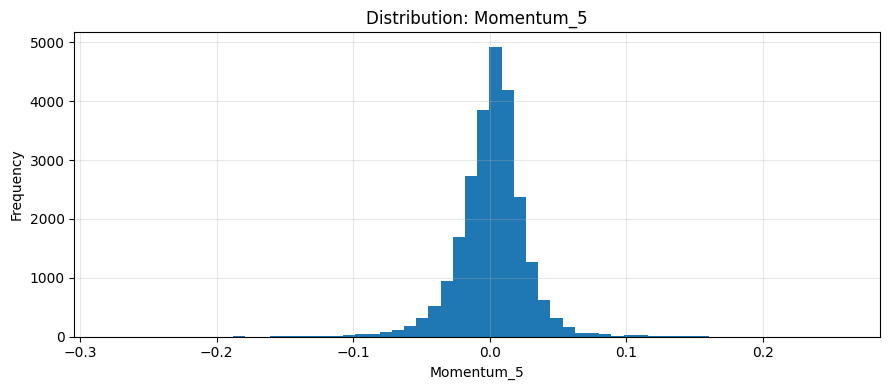

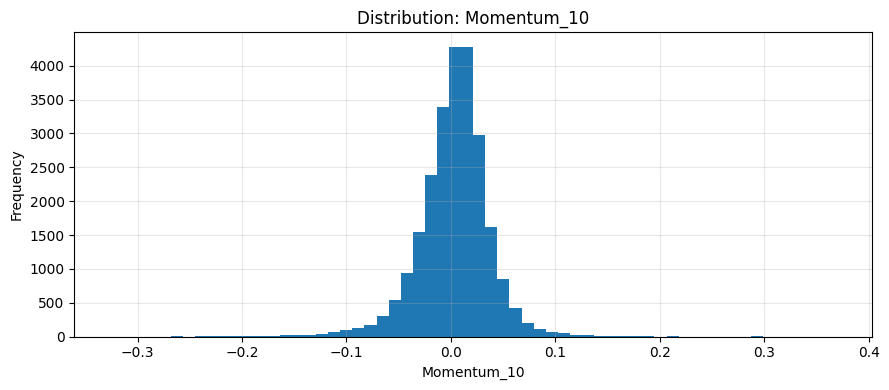

In [21]:
# ============================================================
# CELL 14 - EDA: FEATURE DISTRIBUTIONS
# ============================================================

for feature in FEATURES:
    plt.figure(figsize=(9, 4))
    plt.hist(
        df[feature].dropna(),
        bins=60
    )
    plt.title(f"Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


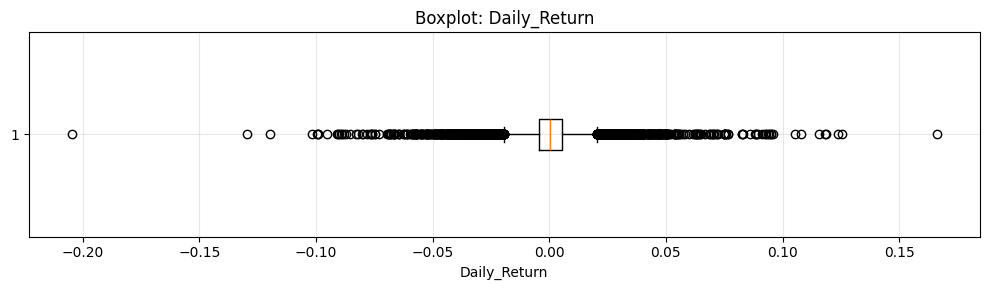

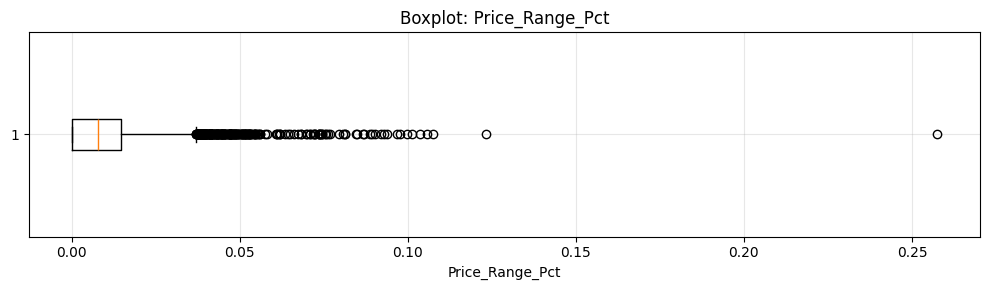

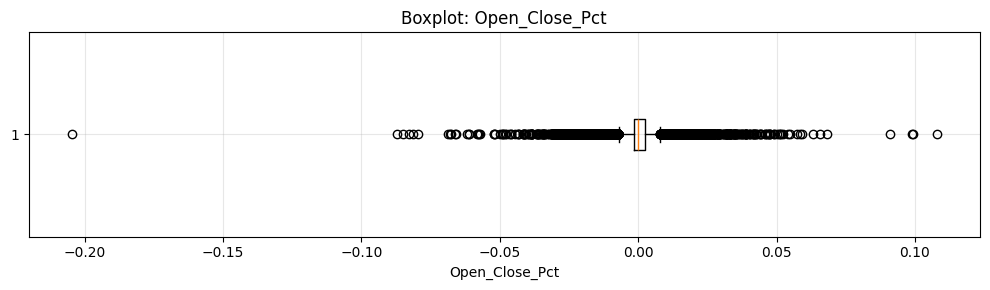

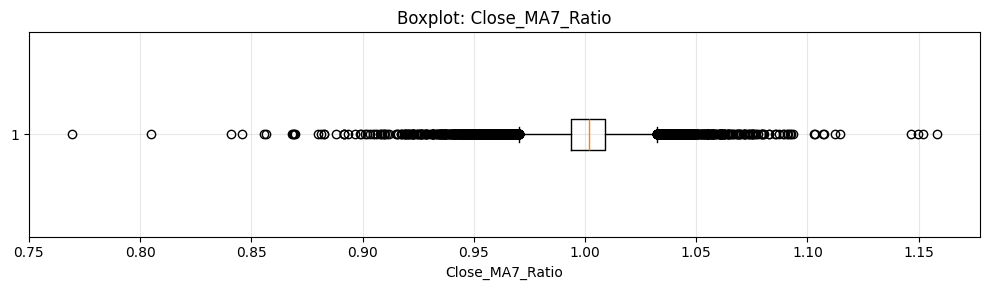

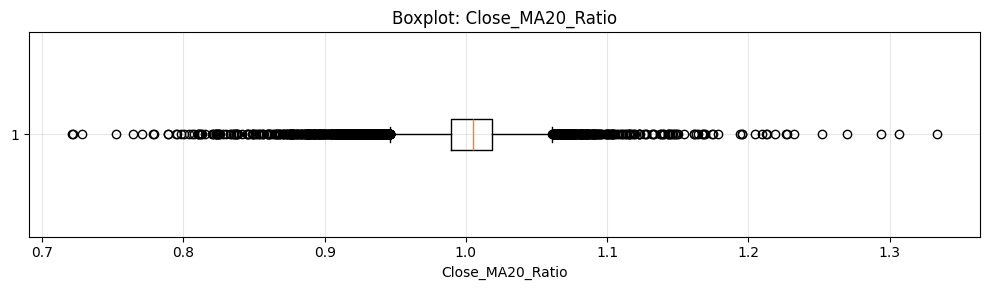

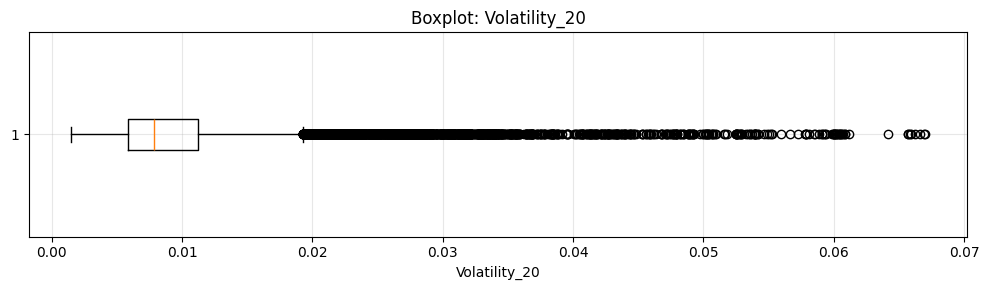

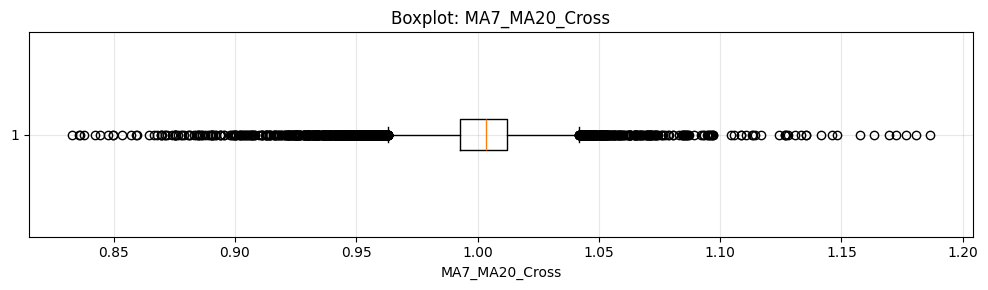

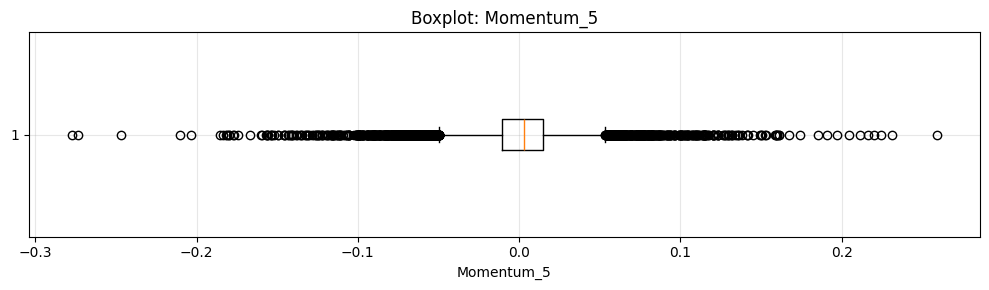

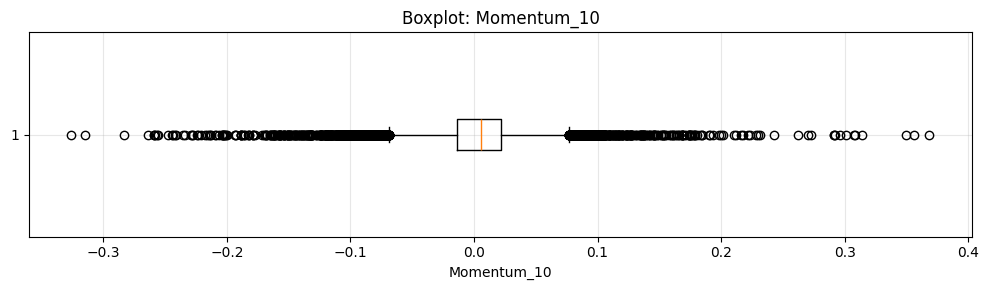

In [22]:
# ============================================================
# CELL 15 - EDA: BOXPLOTS / OUTLIERS
# ============================================================

for feature in FEATURES:
    plt.figure(figsize=(10, 3))
    plt.boxplot(
        df[feature].dropna(),
        vert=False
    )
    plt.title(f"Boxplot: {feature}")
    plt.xlabel(feature)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

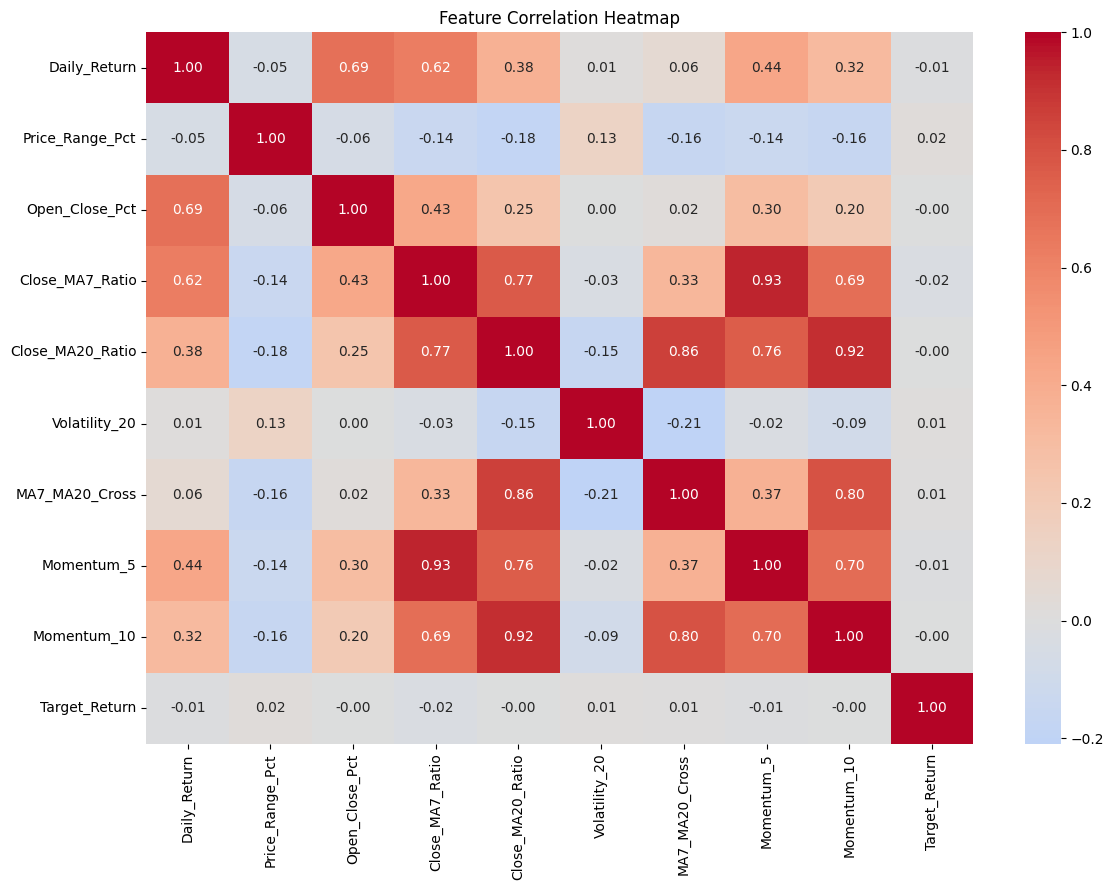

In [23]:
# ============================================================
# CELL 16 - EDA: CORRELATION HEATMAP
# ============================================================

corr = df[
    FEATURES + [TARGET]
].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [24]:
# ============================================================
# CELL 17 - SUMMARY STATISTICS
# ============================================================

display(
    df[
        [
            "Open", "High", "Low",
            "Close", "Volume",
            *FEATURES, TARGET
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Open,24801.0,7.630577e+02,1.334735e+03,4.400000,2.506000e+01,1.039400e+02,1.102590e+03,7.806600e+03
High,24801.0,7.673969e+02,1.341641e+03,4.400000,2.506000e+01,1.048000e+02,1.109240e+03,7.816700e+03
Low,24801.0,7.584508e+02,1.327356e+03,4.400000,2.506000e+01,1.031300e+02,1.094630e+03,7.776310e+03
Close,24801.0,7.632184e+02,1.334990e+03,4.400000,2.506000e+01,1.039400e+02,1.102830e+03,7.798990e+03
Volume,24801.0,9.950448e+08,1.715115e+09,0.000000,1.630000e+06,2.323000e+07,1.238000e+09,1.145623e+10
Daily_Return,24800.0,3.163643e-04,1.190810e-02,-0.204669,-4.528379e-03,4.977851e-04,5.475628e-03,1.660959e-01
Price_Range_Pct,24801.0,9.080598e-03,9.574264e-03,0.000000,0.000000e+00,7.803825e-03,1.477216e-02,2.573831e-01
Open_Close_Pct,24801.0,1.869966e-04,7.872038e-03,-0.204669,-1.428118e-03,0.000000e+00,2.361126e-03,1.078901e-01
Close_MA7_Ratio,24795.0,1.000785e+00,1.588649e-02,0.769311,9.936034e-01,1.001968e+00,1.009046e+00,1.158163e+00
Close_MA20_Ratio,24782.0,1.002533e+00,2.898575e-02,0.721042,9.894966e-01,1.005295e+00,1.018174e+00,1.333333e+00


In [25]:
# ============================================================
# CELL 18 - TREND LABEL
# ============================================================

THRESHOLD = 0.005

def return_to_trend(
    returns,
    threshold=THRESHOLD
):
    returns = np.asarray(returns)

    return np.select(
        [
            returns > threshold,
            returns < -threshold
        ],
        [
            "Bullish",
            "Bearish"
        ],
        default="Neutral"
    )



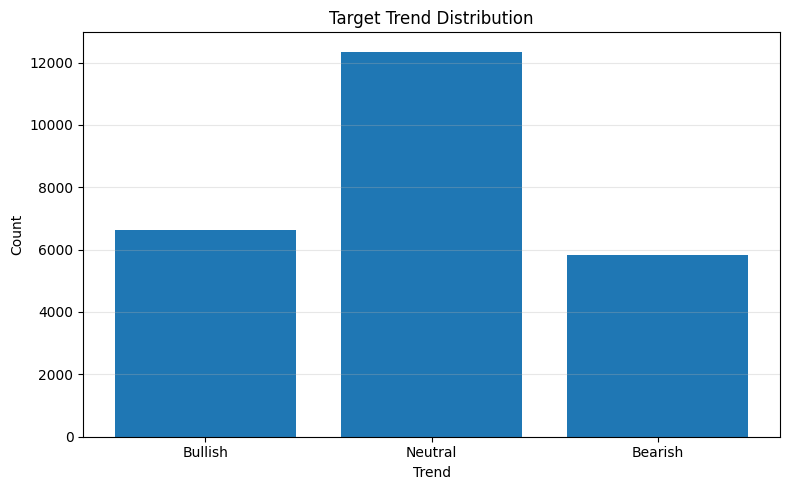

,Count,Percentage
Bullish,6636,26.76
Neutral,12351,49.80
Bearish,5813,23.44


In [26]:
# ============================================================
# CELL 19 - TARGET TREND DISTRIBUTION
# ============================================================

trend_labels = return_to_trend(
    df[TARGET].dropna().values
)

trend_counts = (
    pd.Series(trend_labels)
    .value_counts()
    .reindex(
        ["Bullish", "Neutral", "Bearish"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 5))
plt.bar(
    trend_counts.index,
    trend_counts.values
)
plt.title("Target Trend Distribution")
plt.xlabel("Trend")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "Count": trend_counts,
        "Percentage": (
            trend_counts /
            trend_counts.sum() * 100
        ).round(2)
    })
)



In [27]:
# ============================================================
# CELL 20 - FINAL MODEL DATASET
# ============================================================

model_df = df[
    [
        "Date",
        "Close",
        *FEATURES,
        TARGET
    ]
].dropna().reset_index(drop=True)

print("Final Model Dataset:", model_df.shape)
display(model_df.head())


Final Model Dataset: (24780, 12)


,Date,Close,Daily_Return,Price_Range_Pct,Open_Close_Pct,Close_MA7_Ratio,Close_MA20_Ratio,Volatility_20,MA7_MA20_Cross,Momentum_5,Momentum_10,Target_Return
0,1928-01-30,17.490000,-0.011306,0.0,0.0,0.994073,0.998430,0.007756,1.004383,-0.008503,0.011567,0.004574
1,1928-01-31,17.570000,0.004574,0.0,0.0,0.997890,1.003541,0.007715,1.005663,-0.007905,0.015607,-0.002277
2,1928-02-01,17.530001,-0.002277,0.0,0.0,0.996508,1.001800,0.007715,1.005311,0.000571,0.015643,0.005704
3,1928-02-02,17.629999,0.005704,0.0,0.0,1.002844,1.007285,0.007523,1.004428,0.000000,0.014384,-0.013046
4,1928-02-03,17.400000,-0.013046,0.0,0.0,0.990727,0.994883,0.007939,1.004194,-0.016393,-0.004577,0.002874


In [28]:
# ============================================================
# CELL 21 - CHRONOLOGICAL 70/15/15 SPLIT
# ============================================================

n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTRAIN:")
print(train_df["Date"].min(), "->", train_df["Date"].max())

print("\nVALIDATION:")
print(val_df["Date"].min(), "->", val_df["Date"].max())

print("\nTEST:")
print(test_df["Date"].min(), "->", test_df["Date"].max())

Train: (17346, 12)
Validation: (3717, 12)
Test: (3717, 12)

TRAIN:
1928-01-30 00:00:00 -> 1997-03-06 00:00:00

VALIDATION:
1997-03-07 00:00:00 -> 2011-12-09 00:00:00

TEST:
2011-12-12 00:00:00 -> 2026-09-24 00:00:00


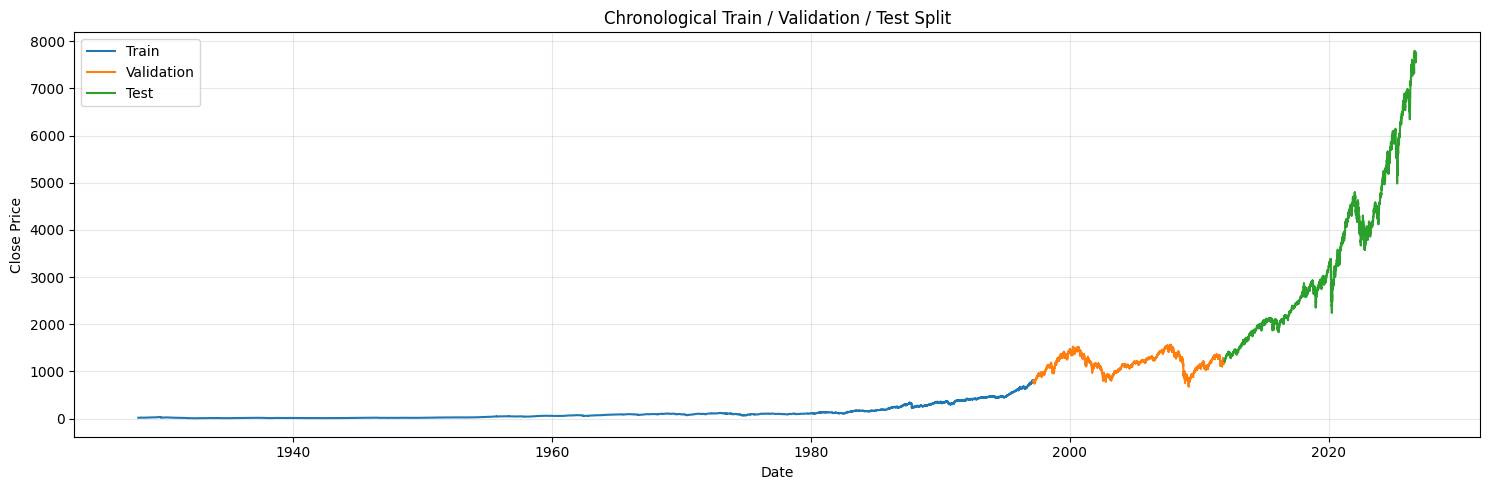

In [29]:
# ============================================================
# CELL 22 - SPLIT VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    train_df["Date"],
    train_df["Close"],
    label="Train"
)

plt.plot(
    val_df["Date"],
    val_df["Close"],
    label="Validation"
)

plt.plot(
    test_df["Date"],
    test_df["Close"],
    label="Test"
)

plt.title("Chronological Train / Validation / Test Split")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:
# ============================================================
# CELL 23 - METRIC HELPERS
# ============================================================

def calculate_regression_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true, y_pred
            )
        ),
        "R2": r2_score(
            y_true, y_pred
        )
    }


def directional_accuracy(y_true, y_pred):

    return np.mean(
        np.sign(np.asarray(y_true))
        ==
        np.sign(np.asarray(y_pred))
    )


In [33]:
# ============================================================
# MODEL 1 - NAIVE PERSISTENCE
# ============================================================

y_train = train_df[TARGET].values
y_val = val_df[TARGET].values
y_test = test_df[TARGET].values

naive_train_pred = np.zeros(len(y_train))
naive_val_pred = np.zeros(len(y_val))
naive_test_pred = np.zeros(len(y_test))

naive_test_metrics = calculate_regression_metrics(
    y_test,
    naive_test_pred
)

naive_directional = directional_accuracy(
    y_test,
    naive_test_pred
)

naive_trend_accuracy = accuracy_score(
    return_to_trend(y_test),
    return_to_trend(naive_test_pred)
)

print("NAIVE PERSISTENCE - TEST")

for key, value in naive_test_metrics.items():
    print(f"{key}: {value:.6f}")

print(f"Directional Accuracy: {naive_directional:.2%}")
print(f"Trend Accuracy: {naive_trend_accuracy:.2%}")

NAIVE PERSISTENCE - TEST
MAE: 0.006923
RMSE: 0.010484
R2: -0.002746
Directional Accuracy: 0.03%
Trend Accuracy: 51.82%


In [35]:
# ============================================================
# MODEL 2 - LINEAR REGRESSION
# ============================================================

X_train = train_df[FEATURES]
X_val = val_df[FEATURES]
X_test = test_df[FEATURES]

linear_feature_scaler = StandardScaler()

X_train_scaled = linear_feature_scaler.fit_transform(
    X_train
)

X_val_scaled = linear_feature_scaler.transform(
    X_val
)

X_test_scaled = linear_feature_scaler.transform(
    X_test
)

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_train_pred = linear_model.predict(
    X_train_scaled
)

linear_val_pred = linear_model.predict(
    X_val_scaled
)

linear_test_pred = linear_model.predict(
    X_test_scaled
)

linear_test_metrics = calculate_regression_metrics(
    y_test,
    linear_test_pred
)

linear_directional = directional_accuracy(
    y_test,
    linear_test_pred
)

linear_trend_accuracy = accuracy_score(
    return_to_trend(y_test),
    return_to_trend(linear_test_pred)
)

print("\nLINEAR REGRESSION - TEST")

for key, value in linear_test_metrics.items():
    print(f"{key}: {value:.6f}")

print(f"Directional Accuracy: {linear_directional:.2%}")
print(f"Trend Accuracy: {linear_trend_accuracy:.2%}")



LINEAR REGRESSION - TEST
MAE: 0.006995
RMSE: 0.010637
R2: -0.032182
Directional Accuracy: 50.15%
Trend Accuracy: 51.92%


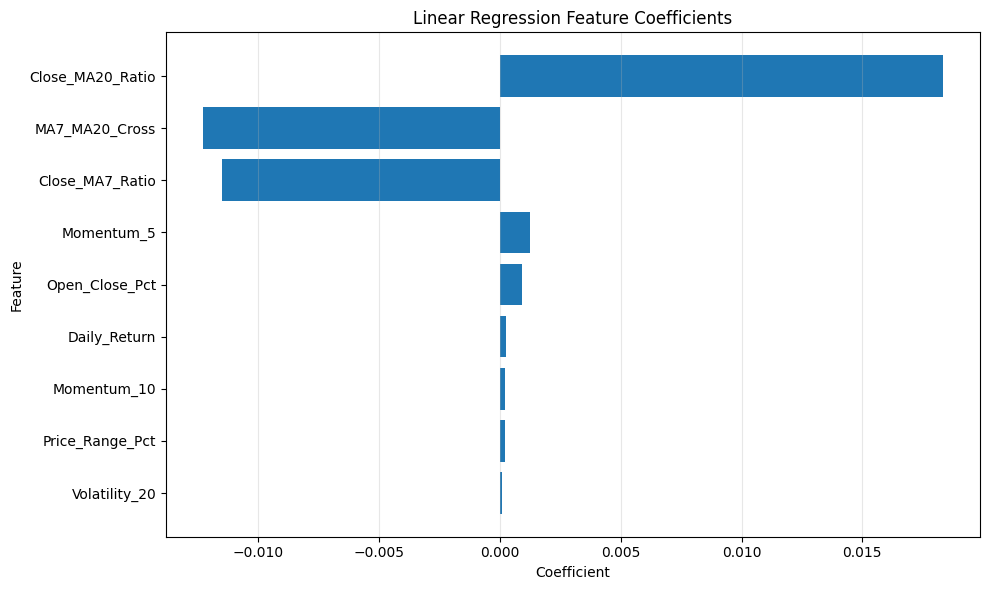

In [36]:
# ============================================================
# VISUALIZATION - LINEAR REGRESSION COEFFICIENTS
# ============================================================

coef_df = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient": linear_model.coef_
})

coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    coef_df["Feature"],
    coef_df["Coefficient"]
)
plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()